RANDOM FOREST CLASSIFIER

Accuracy = 0.9981892258940697

Classification Report

              precision    recall  f1-score   support

         1.0       1.00      1.00      1.00         1
         2.0       1.00      1.00      1.00         2
         3.0       1.00      1.00      1.00         1
         4.0       1.00      1.00      1.00         2
         5.0       1.00      1.00      1.00        55
         6.0       1.00      1.00      1.00         2
         7.0       1.00      1.00      1.00         4
         8.0       1.00      1.00      1.00         7
         9.0       1.00      1.00      1.00        40
        10.0       1.00      1.00      1.00         5
        11.0       1.00      1.00      1.00        11
        12.0       1.00      1.00      1.00         1
        13.0       1.00      1.00      1.00        18
        14.0       1.00      1.00      1.00         1
        15.0       1.00      1.00      1.00         1
        16.0       1.00      1.00      1.00         2
 

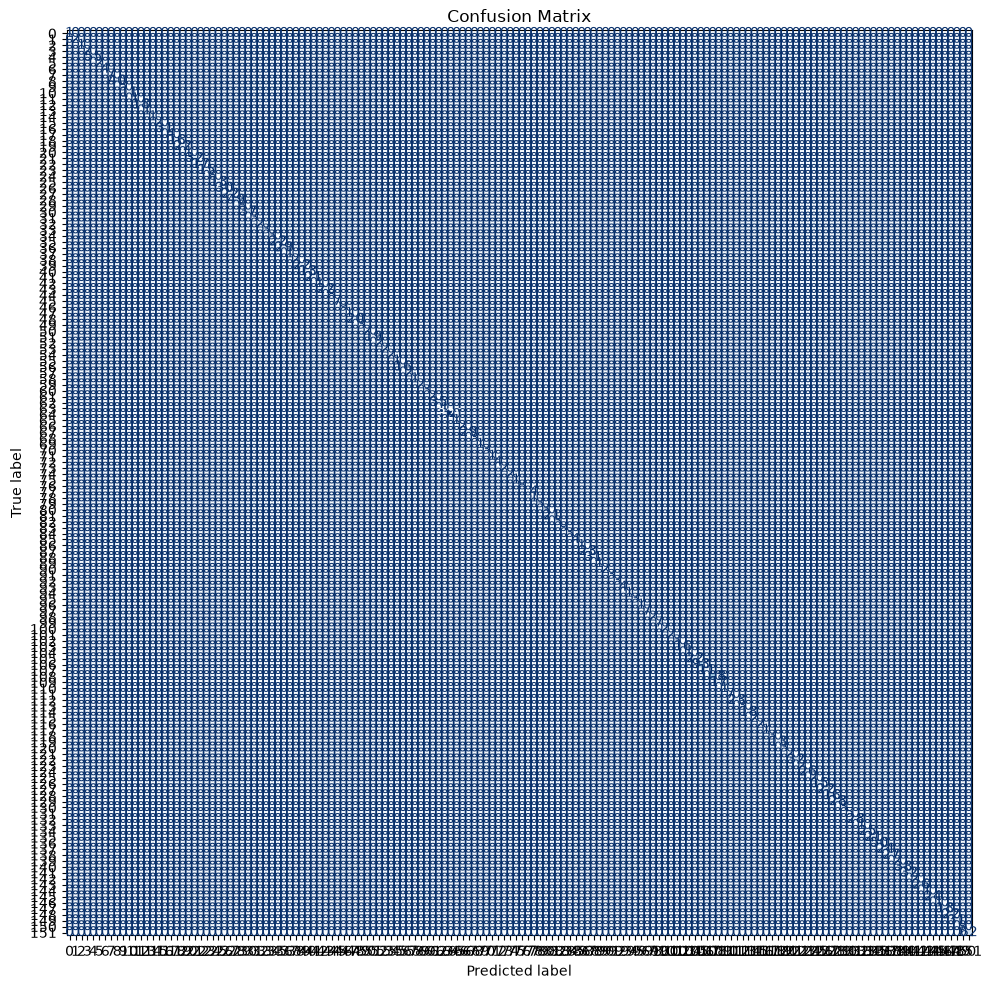


Feature Importance

     Feature  Importance
0   LATITUDE    0.502437
1  LONGITUDE    0.497563


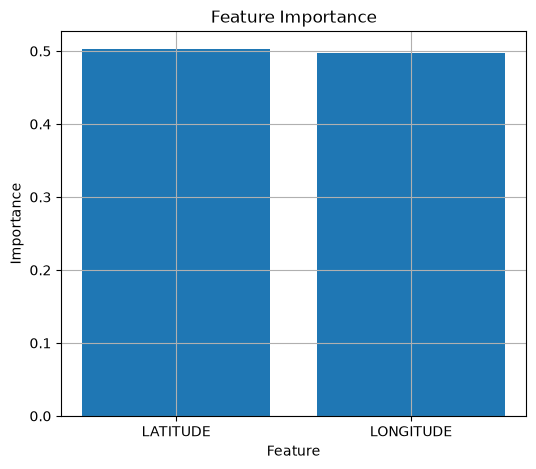


Prediction file saved successfully.


In [5]:
# ==========================================================
# RANDOM FOREST CLASSIFIER
# Latitude + Longitude ---> TownCode
# ==========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ==========================================================
# Load Excel File
# ==========================================================

file_path = r"Road_noise_measurements_filled (1).xlsx"
df = pd.read_excel(
    file_path,
    sheet_name="Road_noise_measurements"
)

# ==========================================================
# Create TownCode
# (Latitude -> Longitude Order)
# ==========================================================

town_locations = (
    df.groupby("TOWN")[["LATITUDE","LONGITUDE"]]
      .first()
      .reset_index()
)

town_locations = town_locations.sort_values(
    by=["LATITUDE","LONGITUDE"]
).reset_index(drop=True)

town_locations["TownCode"] = np.arange(
    1,
    len(town_locations)+1
)

df = df.merge(
    town_locations[["TOWN","TownCode"]],
    on="TOWN",
    how="left"
)

# ==========================================================
# Select Variables
# ==========================================================

X = df[["LATITUDE","LONGITUDE"]]

Y = df["TownCode"]

# ==========================================================
# Remove Missing Values
# ==========================================================

data = pd.concat([X,Y],axis=1)

data = data.dropna()

X = data[["LATITUDE","LONGITUDE"]]

Y = data["TownCode"]

# ==========================================================
# Train Test Split
# ==========================================================

X_train,X_test,Y_train,Y_test = train_test_split(
    X,
    Y,
    test_size=0.30,
    random_state=42
)

# ==========================================================
# Build Random Forest
# ==========================================================

model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    criterion="gini"
)

model.fit(
    X_train,
    Y_train
)

# ==========================================================
# Prediction
# ==========================================================

Y_pred = model.predict(X_test)

# ==========================================================
# Accuracy
# ==========================================================

accuracy = accuracy_score(
    Y_test,
    Y_pred
)

print("="*70)
print("RANDOM FOREST CLASSIFIER")
print("="*70)

print("\nAccuracy =",accuracy)

# ==========================================================
# Classification Report
# ==========================================================

print("\nClassification Report\n")

print(
    classification_report(
        Y_test,
        Y_pred,
        zero_division=0
    )
)

# ==========================================================
# Confusion Matrix
# ==========================================================

cm = confusion_matrix(
    Y_test,
    Y_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm
)

fig,ax = plt.subplots(figsize=(12,10))

disp.plot(ax=ax,
          cmap="Blues",
          colorbar=False)

plt.title("Confusion Matrix")

plt.tight_layout()

plt.show()

# ==========================================================
# Feature Importance
# ==========================================================

importance = pd.DataFrame({
    "Feature":X.columns,
    "Importance":model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print("\nFeature Importance\n")

print(importance)

# ==========================================================
# Feature Importance Plot
# ==========================================================

plt.figure(figsize=(6,5))

plt.bar(
    importance["Feature"],
    importance["Importance"]
)

plt.xlabel("Feature")

plt.ylabel("Importance")

plt.title("Feature Importance")

plt.grid(True)

plt.show()

# ==========================================================
# Prediction File
# ==========================================================

results = X_test.copy()

results["Actual_TownCode"] = Y_test.values

results["Predicted_TownCode"] = Y_pred

results.to_excel(
    "RF_TownCode_Predictions.xlsx",
    index=False
)

print("\nPrediction file saved successfully.")

RANDOM FOREST CLASSIFIER
AVG_NOISE_LVL ---> Risk_Level

Accuracy : 1.0

Classification Report

              precision    recall  f1-score   support

         1.0       1.00      1.00      1.00       289
         3.0       1.00      1.00      1.00       874

    accuracy                           1.00      1163
   macro avg       1.00      1.00      1.00      1163
weighted avg       1.00      1.00      1.00      1163



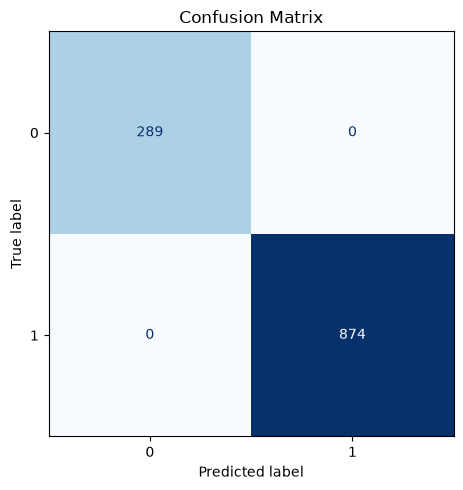


Feature Importance

         Feature  Importance
0  AVG_NOISE_LVL         1.0


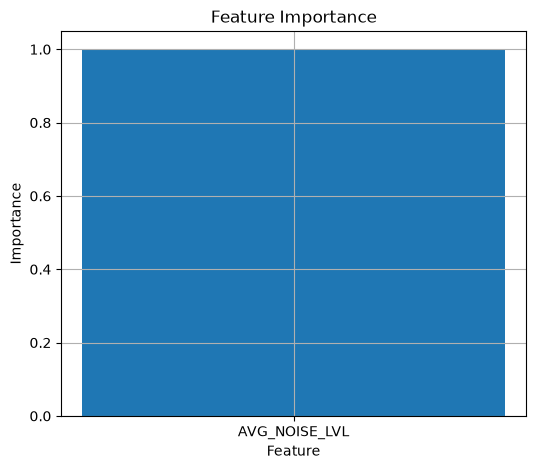

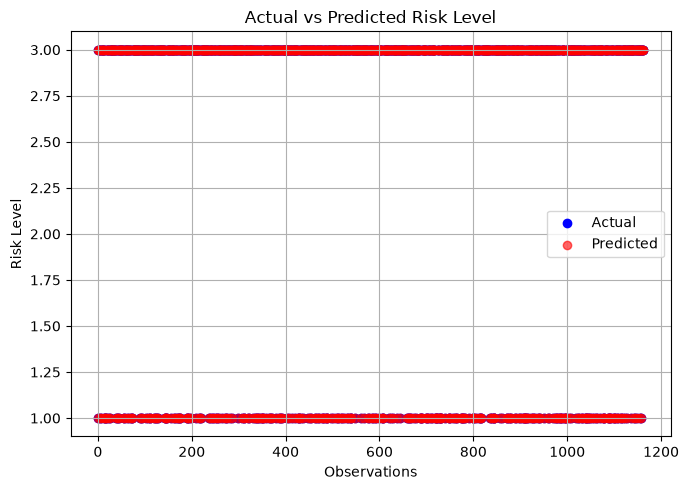


Prediction file saved successfully.

Random Forest Classifier Completed Successfully.


In [6]:
# ==========================================================
# RANDOM FOREST CLASSIFIER
# AVG_NOISE_LVL ---> Risk_Level
# ==========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ==========================================================
# Load Excel File
# ==========================================================

file_path = r"Road_noise_measurements_filled (1).xlsx"

df = pd.read_excel(
    file_path,
    sheet_name="Road_noise_measurements"
)

# ==========================================================
# Convert Risk Level
# ==========================================================

df["Risk_Level"] = (
    df["Risk_Level"]
      .astype(str)
      .str.strip()
      .str.lower()
)

risk_mapping = {
    "low":1,
    "medium":2,
    "high":3
}

df["Risk_Level"] = df["Risk_Level"].map(risk_mapping)

# ==========================================================
# Select Variables
# ==========================================================

X = df[["AVG_NOISE_LVL"]]

Y = df["Risk_Level"]

# ==========================================================
# Remove Missing Values
# ==========================================================

data = pd.concat([X,Y],axis=1)

data = data.dropna()

X = data[["AVG_NOISE_LVL"]]

Y = data["Risk_Level"]

# ==========================================================
# Train Test Split
# ==========================================================

X_train,X_test,Y_train,Y_test = train_test_split(
    X,
    Y,
    test_size=0.30,
    random_state=42,
    stratify=Y
)

# ==========================================================
# Build Random Forest
# ==========================================================

model = RandomForestClassifier(
    n_estimators=300,
    criterion="gini",
    random_state=42
)

model.fit(
    X_train,
    Y_train
)

# ==========================================================
# Prediction
# ==========================================================

Y_pred = model.predict(X_test)

# ==========================================================
# Accuracy
# ==========================================================

accuracy = accuracy_score(
    Y_test,
    Y_pred
)

print("="*70)
print("RANDOM FOREST CLASSIFIER")
print("AVG_NOISE_LVL ---> Risk_Level")
print("="*70)

print("\nAccuracy :",accuracy)

# ==========================================================
# Classification Report
# ==========================================================

print("\nClassification Report\n")

print(
    classification_report(
        Y_test,
        Y_pred,
        zero_division=0
    )
)

# ==========================================================
# Confusion Matrix
# ==========================================================

cm = confusion_matrix(
    Y_test,
    Y_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm
)

fig,ax = plt.subplots(figsize=(6,5))

disp.plot(
    ax=ax,
    cmap="Blues",
    colorbar=False
)

plt.title("Confusion Matrix")

plt.tight_layout()

plt.show()

# ==========================================================
# Feature Importance
# ==========================================================

importance = pd.DataFrame({

    "Feature":X.columns,

    "Importance":model.feature_importances_

})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print("\nFeature Importance\n")

print(importance)

# ==========================================================
# Feature Importance Plot
# ==========================================================

plt.figure(figsize=(6,5))

plt.bar(
    importance["Feature"],
    importance["Importance"]
)

plt.xlabel("Feature")

plt.ylabel("Importance")

plt.title("Feature Importance")

plt.grid(True)

plt.show()

# ==========================================================
# Actual vs Predicted Plot
# ==========================================================

plt.figure(figsize=(7,5))

plt.scatter(
    range(len(Y_test)),
    Y_test,
    label="Actual",
    color="blue"
)

plt.scatter(
    range(len(Y_pred)),
    Y_pred,
    label="Predicted",
    color="red",
    alpha=0.6
)

plt.xlabel("Observations")

plt.ylabel("Risk Level")

plt.title("Actual vs Predicted Risk Level")

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()

# ==========================================================
# Save Prediction
# ==========================================================

results = X_test.copy()

results["Actual_Risk_Level"] = Y_test.values

results["Predicted_Risk_Level"] = Y_pred

results.to_excel(
    "RF_RiskLevel_Predictions.xlsx",
    index=False
)

print("\nPrediction file saved successfully.")

print("\nRandom Forest Classifier Completed Successfully.")

RANDOM FOREST REGRESSOR
AVG_NOISE_LVL ---> Duration_hours
R² Score : -0.0207
RMSE     : 4.3841
MAE      : 3.6681

Feature Importance

         Feature  Importance
0  AVG_NOISE_LVL         1.0


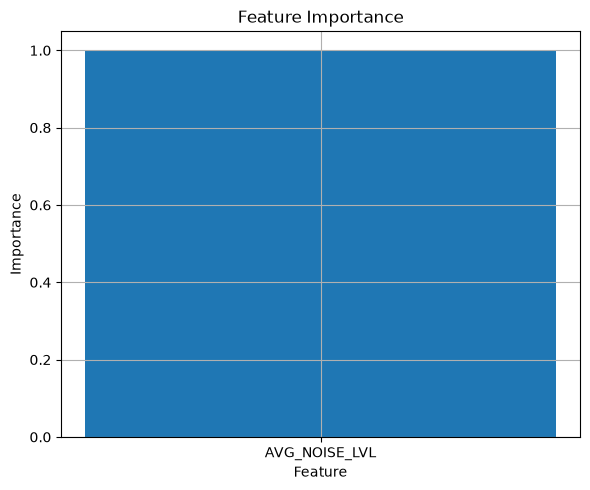

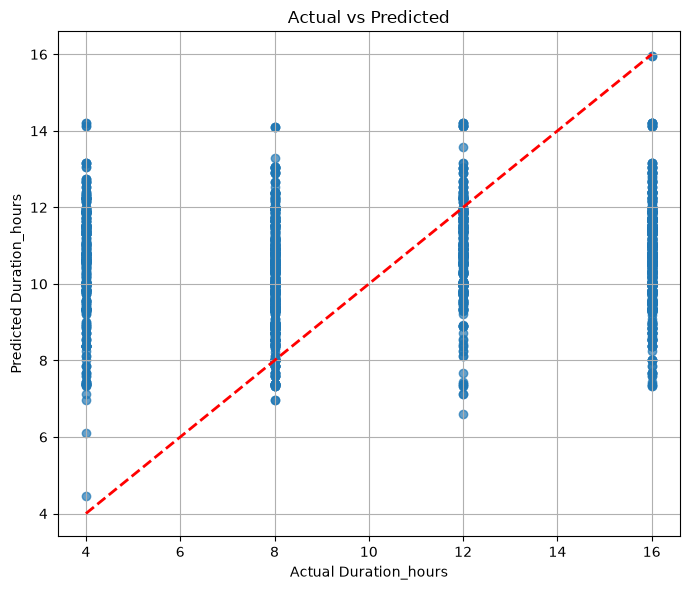

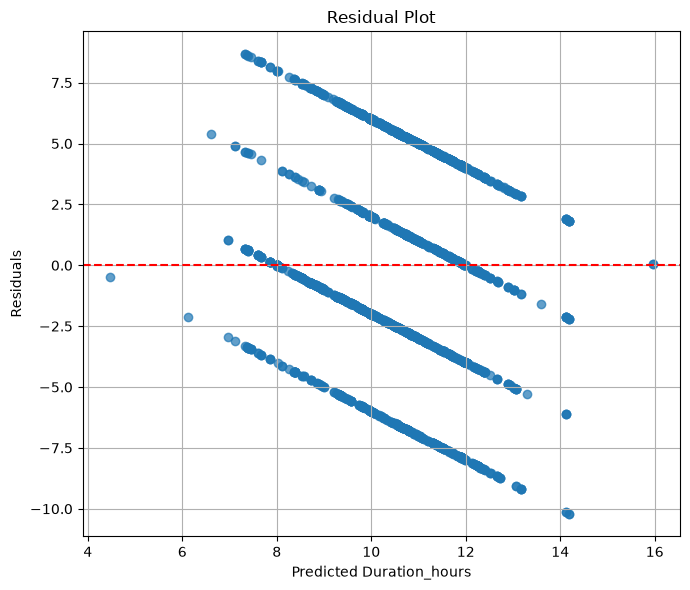


Prediction file saved successfully.

Random Forest Regressor Completed Successfully.


In [7]:
# ==========================================================
# RANDOM FOREST REGRESSOR
# AVG_NOISE_LVL ---> Duration_hours
# ==========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# ==========================================================
# Load Excel File
# ==========================================================

file_path = r"Road_noise_measurements_filled (1).xlsx"
df = pd.read_excel(
    file_path,
    sheet_name="Road_noise_measurements"
)

# ==========================================================
# Select Variables
# ==========================================================

X = df[["AVG_NOISE_LVL"]]

Y = df["Duration_hours"]

# ==========================================================
# Remove Missing Values
# ==========================================================

data = pd.concat([X, Y], axis=1)

data = data.dropna()

X = data[["AVG_NOISE_LVL"]]

Y = data["Duration_hours"]

# ==========================================================
# Train-Test Split
# ==========================================================

X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y,
    test_size=0.30,
    random_state=42
)

# ==========================================================
# Build Random Forest Regressor
# ==========================================================

model = RandomForestRegressor(
    n_estimators=300,
    random_state=42
)

model.fit(X_train, Y_train)

# ==========================================================
# Prediction
# ==========================================================

Y_pred = model.predict(X_test)

# ==========================================================
# Evaluation Metrics
# ==========================================================

mse = mean_squared_error(Y_test, Y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(Y_test, Y_pred)
r2 = r2_score(Y_test, Y_pred)

print("="*70)
print("RANDOM FOREST REGRESSOR")
print("AVG_NOISE_LVL ---> Duration_hours")
print("="*70)

print(f"R² Score : {r2:.4f}")
print(f"RMSE     : {rmse:.4f}")
print(f"MAE      : {mae:.4f}")

# ==========================================================
# Feature Importance
# ==========================================================

importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

print("\nFeature Importance\n")
print(importance)

# ==========================================================
# Feature Importance Plot
# ==========================================================

plt.figure(figsize=(6,5))

plt.bar(
    importance["Feature"],
    importance["Importance"]
)

plt.xlabel("Feature")
plt.ylabel("Importance")
plt.title("Feature Importance")

plt.grid(True)

plt.tight_layout()

plt.show()

# ==========================================================
# Actual vs Predicted Plot
# ==========================================================

plt.figure(figsize=(7,6))

plt.scatter(
    Y_test,
    Y_pred,
    alpha=0.7
)

plt.plot(
    [Y_test.min(), Y_test.max()],
    [Y_test.min(), Y_test.max()],
    'r--',
    linewidth=2
)

plt.xlabel("Actual Duration_hours")
plt.ylabel("Predicted Duration_hours")

plt.title("Actual vs Predicted")

plt.grid(True)

plt.tight_layout()

plt.show()

# ==========================================================
# Residual Plot
# ==========================================================

residuals = Y_test - Y_pred

plt.figure(figsize=(7,6))

plt.scatter(
    Y_pred,
    residuals,
    alpha=0.7
)

plt.axhline(
    0,
    color="red",
    linestyle="--"
)

plt.xlabel("Predicted Duration_hours")
plt.ylabel("Residuals")

plt.title("Residual Plot")

plt.grid(True)

plt.tight_layout()

plt.show()

# ==========================================================
# Prediction File
# ==========================================================

results = X_test.copy()

results["Actual_Duration"] = Y_test.values
results["Predicted_Duration"] = Y_pred

results.to_excel(
    "RF_Duration_Predictions.xlsx",
    index=False
)

print("\nPrediction file saved successfully.")

print("\nRandom Forest Regressor Completed Successfully.")

RANDOM FOREST CLASSIFIER
Duration_hours ---> Risk_Level

Accuracy : 0.8229

Classification Report

              precision    recall  f1-score   support

         1.0       0.63      0.70      0.66       289
         3.0       0.90      0.86      0.88       874

    accuracy                           0.82      1163
   macro avg       0.76      0.78      0.77      1163
weighted avg       0.83      0.82      0.83      1163



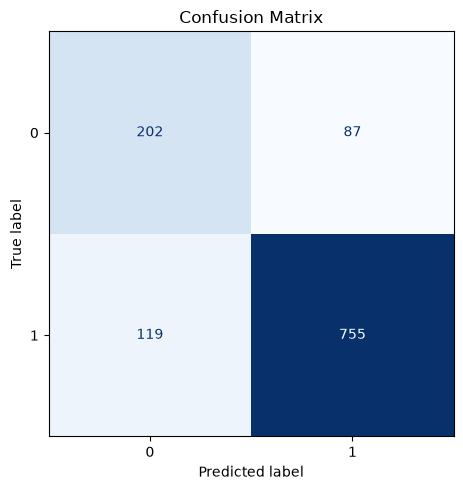


Feature Importance

          Feature  Importance
0  Duration_hours         1.0


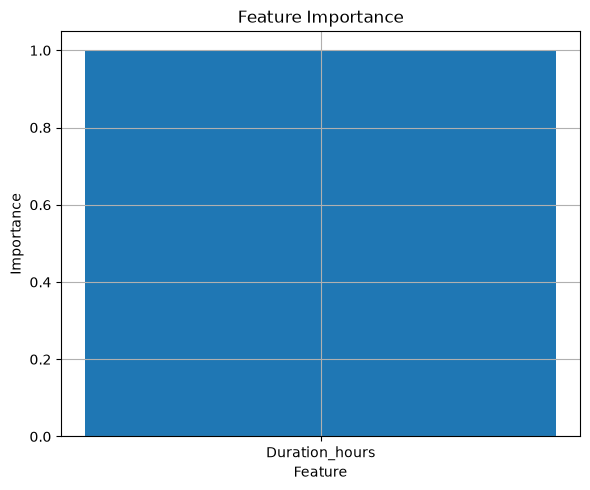

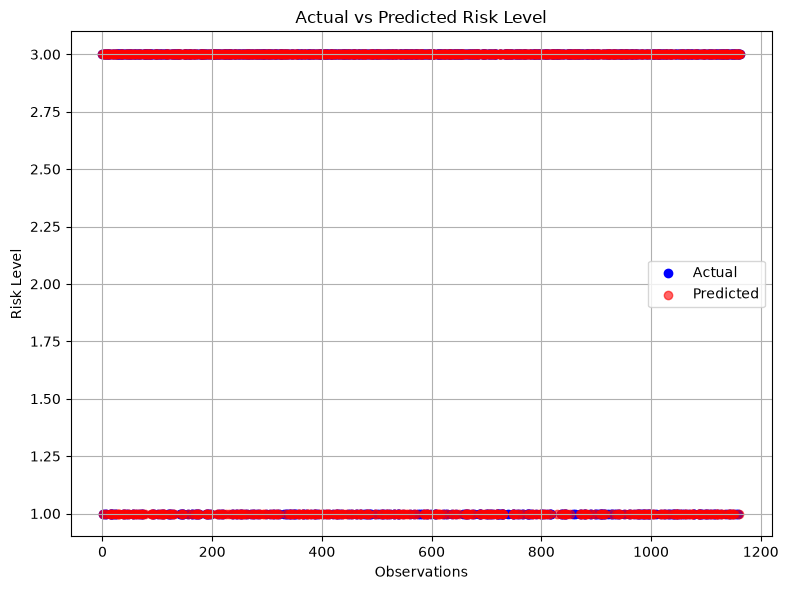


Probability Matrix Shape : (1163, 2)

First Five Probability Rows

[[0.17445041 0.82554959]
 [0.63065636 0.36934364]
 [0.01338727 0.98661273]
 [0.02503548 0.97496452]
 [0.02503548 0.97496452]]

Prediction file saved successfully.

Random Forest Classifier Completed Successfully.


In [8]:
# ==========================================================
# RANDOM FOREST CLASSIFIER
# Duration_hours ---> Risk_Level
# ==========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ==========================================================
# Load Excel File
# ==========================================================

file_path = r"Road_noise_measurements_filled (1).xlsx"
df = pd.read_excel(
    file_path,
    sheet_name="Road_noise_measurements"
)

# ==========================================================
# Convert Risk Level to Numeric
# ==========================================================

df["Risk_Level"] = (
    df["Risk_Level"]
      .astype(str)
      .str.strip()
      .str.lower()
)

risk_mapping = {
    "low": 1,
    "medium": 2,
    "high": 3
}

df["Risk_Level"] = df["Risk_Level"].map(risk_mapping)

# ==========================================================
# Select Variables
# ==========================================================

X = df[["Duration_hours"]]

Y = df["Risk_Level"]

# ==========================================================
# Remove Missing Values
# ==========================================================

data = pd.concat([X, Y], axis=1)

data = data.dropna()

X = data[["Duration_hours"]]

Y = data["Risk_Level"]

# ==========================================================
# Train Test Split
# ==========================================================

X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y,
    test_size=0.30,
    random_state=42,
    stratify=Y
)

# ==========================================================
# Build Random Forest Classifier
# ==========================================================

model = RandomForestClassifier(
    n_estimators=300,
    criterion="gini",
    random_state=42
)

model.fit(X_train, Y_train)

# ==========================================================
# Prediction
# ==========================================================

Y_pred = model.predict(X_test)

# ==========================================================
# Accuracy
# ==========================================================

accuracy = accuracy_score(Y_test, Y_pred)

print("="*70)
print("RANDOM FOREST CLASSIFIER")
print("Duration_hours ---> Risk_Level")
print("="*70)

print(f"\nAccuracy : {accuracy:.4f}")

# ==========================================================
# Classification Report
# ==========================================================

print("\nClassification Report\n")

print(
    classification_report(
        Y_test,
        Y_pred,
        zero_division=0
    )
)

# ==========================================================
# Confusion Matrix
# ==========================================================

cm = confusion_matrix(Y_test, Y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)

fig, ax = plt.subplots(figsize=(6,5))

disp.plot(
    ax=ax,
    cmap="Blues",
    colorbar=False
)

plt.title("Confusion Matrix")

plt.tight_layout()

plt.show()

# ==========================================================
# Feature Importance
# ==========================================================

importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

print("\nFeature Importance\n")

print(importance)

# ==========================================================
# Feature Importance Plot
# ==========================================================

plt.figure(figsize=(6,5))

plt.bar(
    importance["Feature"],
    importance["Importance"]
)

plt.xlabel("Feature")

plt.ylabel("Importance")

plt.title("Feature Importance")

plt.grid(True)

plt.tight_layout()

plt.show()

# ==========================================================
# Actual vs Predicted Plot
# ==========================================================

plt.figure(figsize=(8,6))

plt.scatter(
    range(len(Y_test)),
    Y_test,
    label="Actual",
    color="blue"
)

plt.scatter(
    range(len(Y_pred)),
    Y_pred,
    label="Predicted",
    color="red",
    alpha=0.6
)

plt.xlabel("Observations")

plt.ylabel("Risk Level")

plt.title("Actual vs Predicted Risk Level")

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()

# ==========================================================
# Prediction Probabilities
# ==========================================================

prob = model.predict_proba(X_test)

print("\nProbability Matrix Shape :", prob.shape)

print("\nFirst Five Probability Rows\n")

print(prob[:5])

# ==========================================================
# Save Predictions
# ==========================================================

results = X_test.copy()

results["Actual_Risk_Level"] = Y_test.values

results["Predicted_Risk_Level"] = Y_pred

results.to_excel(
    "RF_Duration_vs_RiskLevel.xlsx",
    index=False
)

print("\nPrediction file saved successfully.")

print("\nRandom Forest Classifier Completed Successfully.")

RANDOM FOREST REGRESSOR
Longitude ---> Duration_hours
R² Score : -0.0857
RMSE     : 4.5215
MAE      : 4.0839

Feature Importance

     Feature  Importance
0  LONGITUDE         1.0


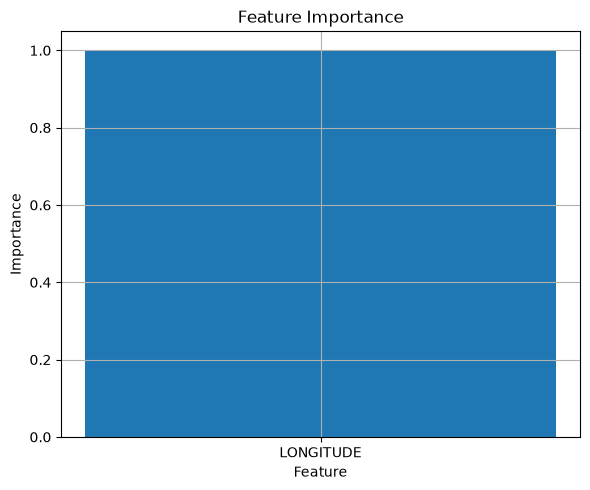

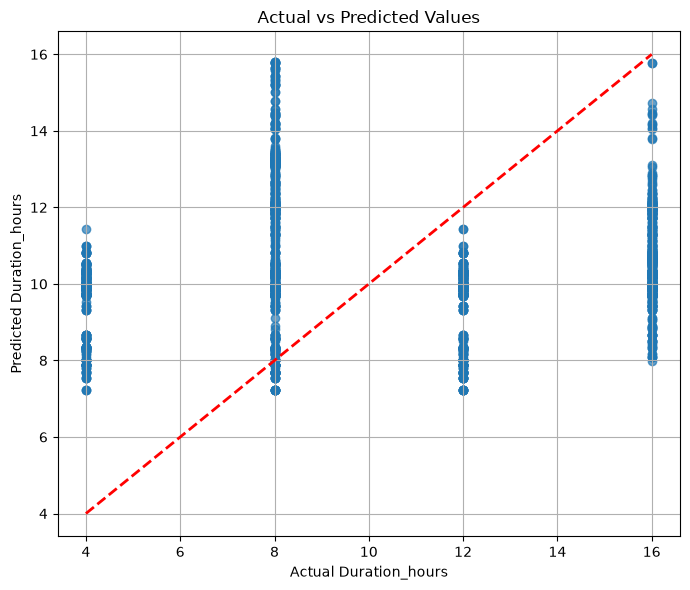

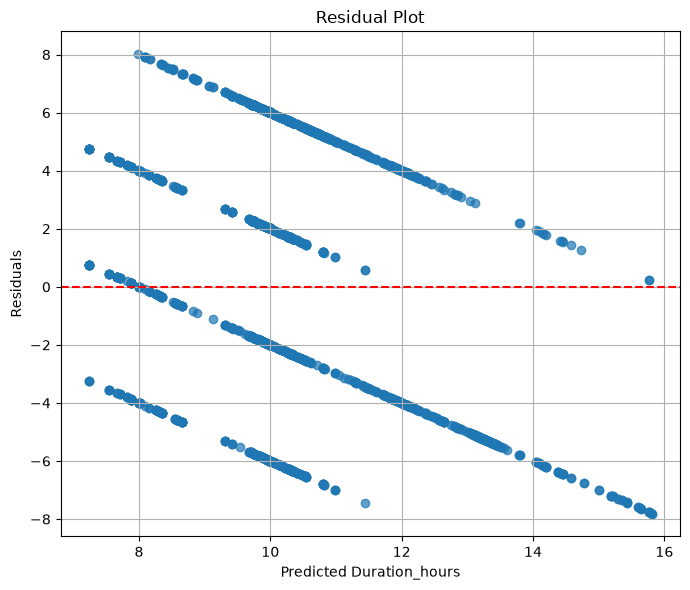

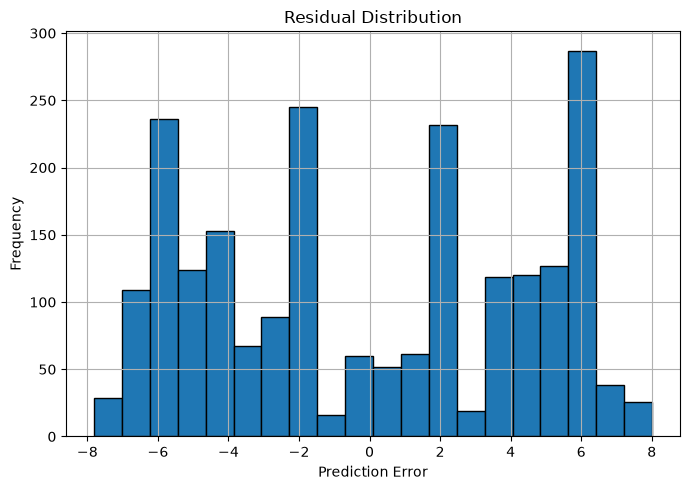


Prediction file saved successfully.

Random Forest Regressor Completed Successfully.


In [9]:
# ==========================================================
# RANDOM FOREST REGRESSOR
# Longitude ---> Duration_hours
# ==========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# ==========================================================
# Load Excel File
# ==========================================================

file_path = r"Road_noise_measurements_filled (1).xlsx"
df = pd.read_excel(
    file_path,
    sheet_name="Road_noise_measurements"
)

# ==========================================================
# Select Variables
# ==========================================================

X = df[["LONGITUDE"]]

Y = df["Duration_hours"]

# ==========================================================
# Remove Missing Values
# ==========================================================

data = pd.concat([X, Y], axis=1)

data = data.dropna()

X = data[["LONGITUDE"]]

Y = data["Duration_hours"]

# ==========================================================
# Train-Test Split
# ==========================================================

X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y,
    test_size=0.30,
    random_state=42
)

# ==========================================================
# Build Random Forest Regressor
# ==========================================================

model = RandomForestRegressor(
    n_estimators=300,
    criterion="squared_error",
    random_state=42
)

model.fit(X_train, Y_train)

# ==========================================================
# Prediction
# ==========================================================

Y_pred = model.predict(X_test)

# ==========================================================
# Evaluation Metrics
# ==========================================================

mse = mean_squared_error(Y_test, Y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(Y_test, Y_pred)
r2 = r2_score(Y_test, Y_pred)

print("="*70)
print("RANDOM FOREST REGRESSOR")
print("Longitude ---> Duration_hours")
print("="*70)

print(f"R² Score : {r2:.4f}")
print(f"RMSE     : {rmse:.4f}")
print(f"MAE      : {mae:.4f}")

# ==========================================================
# Feature Importance
# ==========================================================

importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

print("\nFeature Importance\n")
print(importance)

# ==========================================================
# Feature Importance Plot
# ==========================================================

plt.figure(figsize=(6,5))

plt.bar(
    importance["Feature"],
    importance["Importance"]
)

plt.xlabel("Feature")
plt.ylabel("Importance")
plt.title("Feature Importance")

plt.grid(True)

plt.tight_layout()

plt.show()

# ==========================================================
# Actual vs Predicted Plot
# ==========================================================

plt.figure(figsize=(7,6))

plt.scatter(
    Y_test,
    Y_pred,
    alpha=0.7
)

plt.plot(
    [Y_test.min(), Y_test.max()],
    [Y_test.min(), Y_test.max()],
    'r--',
    linewidth=2
)

plt.xlabel("Actual Duration_hours")
plt.ylabel("Predicted Duration_hours")
plt.title("Actual vs Predicted Values")

plt.grid(True)

plt.tight_layout()

plt.show()

# ==========================================================
# Residual Plot
# ==========================================================

residuals = Y_test - Y_pred

plt.figure(figsize=(7,6))

plt.scatter(
    Y_pred,
    residuals,
    alpha=0.7
)

plt.axhline(
    0,
    color="red",
    linestyle="--"
)

plt.xlabel("Predicted Duration_hours")
plt.ylabel("Residuals")
plt.title("Residual Plot")

plt.grid(True)

plt.tight_layout()

plt.show()

# ==========================================================
# Prediction Error Histogram
# ==========================================================

plt.figure(figsize=(7,5))

plt.hist(
    residuals,
    bins=20,
    edgecolor="black"
)

plt.xlabel("Prediction Error")
plt.ylabel("Frequency")
plt.title("Residual Distribution")

plt.grid(True)

plt.tight_layout()

plt.show()

# ==========================================================
# Save Predictions
# ==========================================================

results = X_test.copy()

results["Actual_Duration"] = Y_test.values
results["Predicted_Duration"] = Y_pred
results["Residual"] = residuals

results.to_excel(
    "RF_Longitude_vs_Duration.xlsx",
    index=False
)

print("\nPrediction file saved successfully.")

print("\nRandom Forest Regressor Completed Successfully.")